<a href="https://colab.research.google.com/github/torcodex/Time-Series-Practice/blob/main/Prophet_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
import numpy as np
import pandas as pd
from prophet import Prophet
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error

In [54]:
df = pd.read_csv('/content/daily-minimum-temperatures-in-me.csv', on_bad_lines='skip')
df

,Date,"Daily minimum temperatures in Melbourne, Australia, 1981-1990"
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8
...,...,...
3645,1990-12-27,14.0
3646,1990-12-28,13.6
3647,1990-12-29,13.5
3648,1990-12-30,15.7


In [55]:
df.shape

(3650, 2)

In [56]:
df.columns

Index(['Date', 'Daily minimum temperatures in Melbourne, Australia, 1981-1990'], dtype='object')

In [57]:
df.isna().sum()

,0
Date,0
"Daily minimum temperatures in Melbourne, Australia, 1981-1990",0


In [58]:
df.duplicated().sum()

np.int64(0)

In [59]:
df_c = df.copy()

In [60]:
df_c.rename(columns={'Date': 'ds', 'Daily minimum temperatures in Melbourne, Australia, 1981-1990': 'y'}, inplace=True)

In [61]:
df_c

,ds,y
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8
...,...,...
3645,1990-12-27,14.0
3646,1990-12-28,13.6
3647,1990-12-29,13.5
3648,1990-12-30,15.7


In [62]:
df_c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   ds      3650 non-null   object
 1   y       3650 non-null   object
dtypes: object(2)
memory usage: 57.2+ KB


In [63]:
df_c['ds'] = pd.to_datetime(df_c['ds'])

In [64]:
df_c['y'] = pd.to_numeric(df_c['y'], errors='coerce')

# Re-split into training and testing sets
training, testing = df_c[:-12], df_c[-12:]
print("Cleaned dataset shape:", df_c.shape)
print("Training set shape:", training.shape)
print("Testing set shape:", testing.shape)

Cleaned dataset shape: (3650, 2)
Training set shape: (3638, 2)
Testing set shape: (12, 2)


In [65]:
df_c.isna().sum()

,0
ds,0
y,3


In [66]:
df_c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ds      3650 non-null   datetime64[ns]
 1   y       3647 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 57.2 KB


In [67]:
df_c = df_c.dropna()

In [68]:
m = Prophet(weekly_seasonality=True,yearly_seasonality=True,daily_seasonality=False)
m.fit(training)

In [69]:
future = m.make_future_dataframe(periods=12,freq='MS')
future.tail()

,ds
3645,1991-08-01
3646,1991-09-01
3647,1991-10-01
3648,1991-11-01
3649,1991-12-01


In [70]:
forecast = m.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

,ds,yhat,yhat_lower,yhat_upper
3645,1991-08-01,7.702357,4.119946,11.178284
3646,1991-09-01,8.466827,5.198455,11.948302
3647,1991-10-01,10.181259,6.669247,13.701588
3648,1991-11-01,12.124114,8.690008,15.635028
3649,1991-12-01,13.693516,10.489214,17.196593


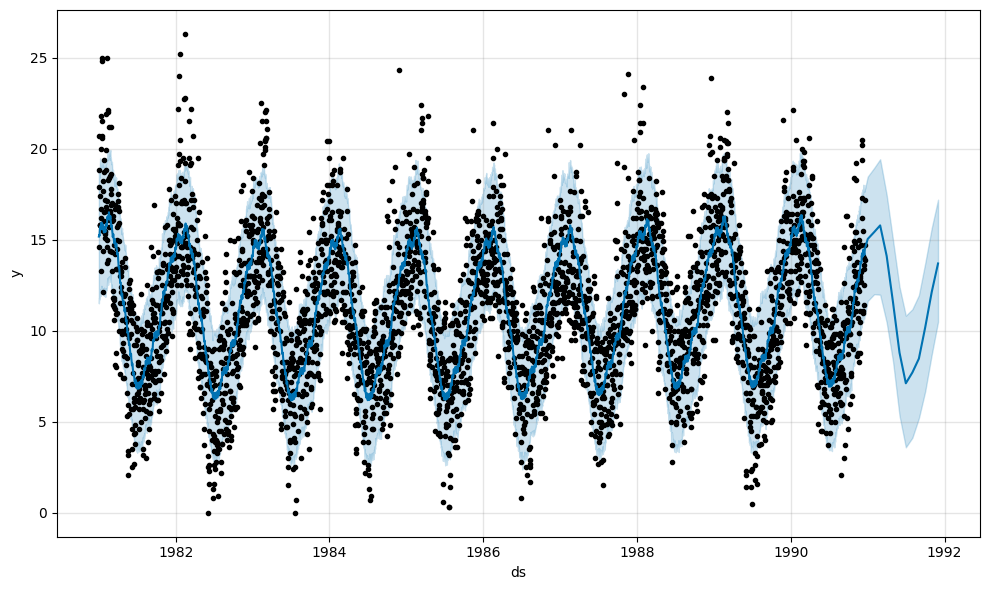

In [71]:
fig1 = m.plot(forecast)

In [77]:
forecast

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,1981-01-01,11.811504,11.504059,18.872372,11.811504,11.811504,3.357573,3.357573,3.357573,0.001877,0.001877,0.001877,3.355695,3.355695,3.355695,0.0,0.0,0.0,15.169077
1,1981-01-02,11.809847,11.813901,18.622000,11.809847,11.809847,3.406171,3.406171,3.406171,-0.023721,-0.023721,-0.023721,3.429892,3.429892,3.429892,0.0,0.0,0.0,15.216018
2,1981-01-03,11.808190,11.707433,18.842890,11.808190,11.808190,3.451479,3.451479,3.451479,-0.051927,-0.051927,-0.051927,3.503407,3.503407,3.503407,0.0,0.0,0.0,15.259669
3,1981-01-04,11.806532,11.748961,18.403363,11.806532,11.806532,3.412308,3.412308,3.412308,-0.162751,-0.162751,-0.162751,3.575059,3.575059,3.575059,0.0,0.0,0.0,15.218841
4,1981-01-05,11.804875,11.814044,18.678763,11.804875,11.804875,3.627804,3.627804,3.627804,-0.015887,-0.015887,-0.015887,3.643690,3.643690,3.643690,0.0,0.0,0.0,15.432679
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3645,1991-08-01,11.654650,4.119946,11.178284,11.611148,11.692776,-3.952292,-3.952292,-3.952292,0.001877,0.001877,0.001877,-3.954170,-3.954170,-3.954170,0.0,0.0,0.0,7.702357
3646,1991-09-01,11.657857,5.198455,11.948302,11.605878,11.702878,-3.191030,-3.191030,-3.191030,-0.162751,-0.162751,-0.162751,-3.028279,-3.028279,-3.028279,0.0,0.0,0.0,8.466827
3647,1991-10-01,11.660961,6.669247,13.701588,11.599499,11.714157,-1.479703,-1.479703,-1.479703,0.085791,0.085791,0.085791,-1.565493,-1.565493,-1.565493,0.0,0.0,0.0,10.181259
3648,1991-11-01,11.664169,8.690008,15.635028,11.593167,11.725350,0.459945,0.459945,0.459945,-0.023721,-0.023721,-0.023721,0.483666,0.483666,0.483666,0.0,0.0,0.0,12.124114


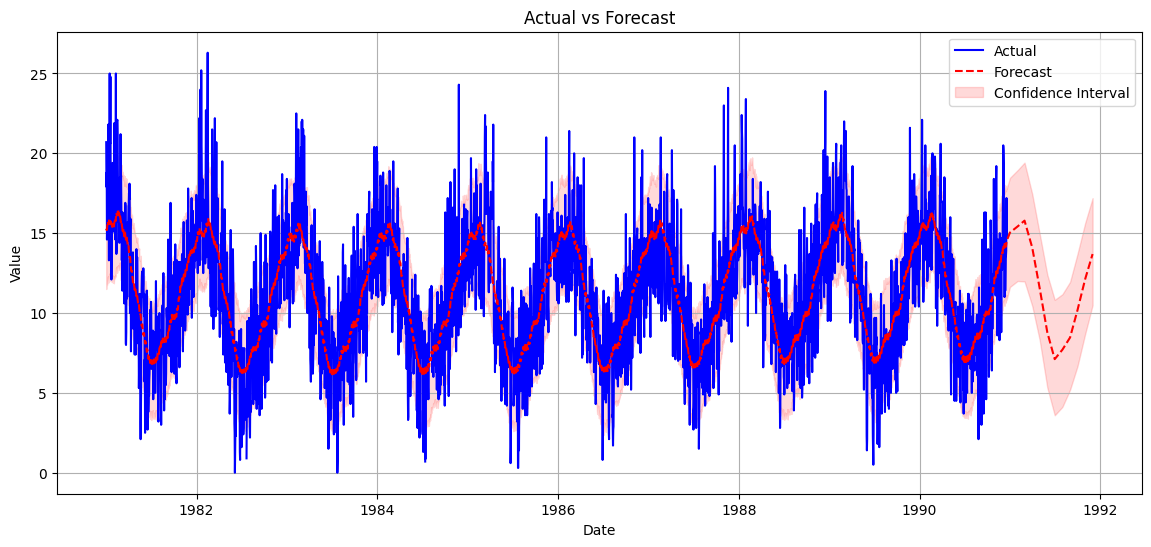

In [72]:
# Create comparison DataFrame using df_c which contains 'ds' and 'y'
comparison = forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].merge(
    df_c[['ds', 'y']],
    on='ds',
    how='left'
)

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(comparison['ds'], comparison['y'],
         label='Actual', color='blue')

plt.plot(comparison['ds'], comparison['yhat'],
         label='Forecast', color='red', linestyle='--')

plt.fill_between(
    comparison['ds'],
    comparison['yhat_lower'],
    comparison['yhat_upper'],
    color='red',
    alpha=0.15,
    label='Confidence Interval'
)

plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Actual vs Forecast')
plt.legend()
plt.grid(True)
plt.show()

In [78]:
# Generate predictions specifically for the test set dates
forecast_test = m.predict(testing[['ds']])

# Extract the forecasted metrics
predictions = forecast_test[['ds', 'yhat', 'yhat_lower', 'yhat_upper']]

# Merge test data with the predictions
comparison = testing.merge(predictions, on='ds', how='left')
comparison

,ds,y,yhat,yhat_lower,yhat_upper
0,1990-12-20,15.4,14.366880,10.965618,17.550925
1,1990-12-21,13.1,14.360421,10.766918,17.765413
2,1990-12-22,13.2,14.356409,10.785513,18.092958
3,1990-12-23,13.9,14.275346,10.977292,17.554818
4,1990-12-24,10.0,14.457877,11.088698,18.124886
5,1990-12-25,12.9,14.601282,11.315366,18.057627
6,1990-12-26,14.6,14.729864,11.092772,18.017484
7,1990-12-27,14.0,14.618681,11.102335,18.126702
8,1990-12-28,13.6,14.652031,11.244646,18.180093
9,1990-12-29,13.5,14.687577,11.066638,18.092009


In [79]:
comparison.isna().sum()

,0
ds,0
y,0
yhat,0
yhat_lower,0
yhat_upper,0


In [80]:
eval = comparison.dropna(subset=['y'])

In [81]:
mse = mean_squared_error(eval['y'], eval['yhat'])
mae = mean_absolute_error(eval['y'], eval['yhat'])
rmse = root_mean_squared_error(eval['y'], eval['yhat'])

print(f'MSE: {mse}')
print(f'MAE: {mae}')
print(f'RMSE: {rmse}')

MSE: 2.866701723839908
MAE: 1.3242039386879993
RMSE: 1.6931336993397503
